<div style="font-family: system-ui, -apple-system, 'Segoe UI', Roboto, sans-serif; max-width: 820px; margin: 12px 0 20px 0; border: 1px solid #cbd5e1; border-radius: 10px; overflow: hidden; box-shadow: 0 4px 10px rgba(15, 23, 42, 0.05);">
  <div style="background: linear-gradient(135deg, #0f172a 0%, #1e3a8a 100%); padding: 24px 28px; color: #ffffff;">
    <div style="font-size: 0.8rem; font-weight: 700; letter-spacing: 0.06em; text-transform: uppercase; color: #93c5fd; margin-bottom: 6px;">
      PpIA: Proyecto Final
    </div>
    <h1 style="margin: 0 0 8px 0; font-size: 1.65rem; font-weight: 700; color: #ffffff;">
      Entrenamiento de Árbol de Decisión - Predicción de Cáncer de Mama
    </h1>
    <p style="margin: 0; font-size: 0.95rem; color: #e2e8f0;">
      Análisis exploratorio, limpieza de datos y clasificación con <code>DecisionTreeClassifier</code> sobre el dataset <em>Breast Cancer Wisconsin (Diagnostic)</em>.
    </p>
  </div>

  <div style="padding: 20px 28px; background-color: #ffffff;">
    <div style="display: flex; flex-wrap: wrap; justify-content: space-between; align-items: center; margin-bottom: 14px; padding-bottom: 10px; border-bottom: 1px solid #cbd5e1;">
      <h2 style="margin: 0; color: #0f172a; font-size: 1.15rem;">Información del Equipo</h2>
      <span style="background-color: #eff6ff; color: #1e3a8a; border: 1px solid #bfdbfe; padding: 4px 12px; border-radius: 999px; font-size: 0.85rem; font-weight: 600;">
        Carrera: Ingeniería en Inteligencia Artificial (IIA)
      </span>
    </div>

<table style="width: 100%; border-collapse: collapse; text-align: left; font-size: 0.92rem; background-color: #ffffff; border: 1px solid #e2e8f0;">
      <thead>
        <tr style="background-color: #1e3a8a; color: #ffffff;">
          <th style="padding: 10px 14px; text-align: center; width: 45px;">#</th>
          <th style="padding: 10px 14px; text-align: left;">Nombre del Integrante</th>
          <th style="padding: 10px 14px; text-align: center; width: 130px;">Matrícula</th>
        </tr>
      </thead>
      <tbody style="color: #1e293b;">
        <tr style="border-bottom: 1px solid #e2e8f0;">
          <td style="padding: 10px 14px; text-align: center; color: #64748b; font-weight: 600;">1</td>
          <td style="padding: 10px 14px;">Gael Sebastián García Azpeytia</td>
          <td style="padding: 10px 14px; text-align: center; font-family: monospace; font-weight: 600;">2164681</td>
        </tr>
        <tr style="border-bottom: 1px solid #e2e8f0; background-color: #f8fafc;">
          <td style="padding: 10px 14px; text-align: center; color: #64748b; font-weight: 600;">2</td>
          <td style="padding: 10px 14px;">Michelle Fernanda Blanco Martínez</td>
          <td style="padding: 10px 14px; text-align: center; font-family: monospace; font-weight: 600;">2182171</td>
        </tr>
        <tr style="border-bottom: 1px solid #e2e8f0;">
          <td style="padding: 10px 14px; text-align: center; color: #64748b; font-weight: 600;">3</td>
          <td style="padding: 10px 14px;">Alexandra Diaz Sandria</td>
          <td style="padding: 10px 14px; text-align: center; font-family: monospace; font-weight: 600;">2276207</td>
        </tr>
        <tr style="border-bottom: 1px solid #e2e8f0; background-color: #f8fafc;">
          <td style="padding: 10px 14px; text-align: center; color: #64748b; font-weight: 600;">4</td>
          <td style="padding: 10px 14px;">Mayté Mendoza Sánchez</td>
          <td style="padding: 10px 14px; text-align: center; font-family: monospace; font-weight: 600;">2189263</td>
        </tr>
        <tr>
          <td style="padding: 10px 14px; text-align: center; color: #64748b; font-weight: 600;">5</td>
          <td style="padding: 10px 14px;">Daniel Alejandro García Echeverría</td>
          <td style="padding: 10px 14px; text-align: center; font-family: monospace; font-weight: 600;">2163681</td>
        </tr>
      </tbody>
    </table>
  </div>
</div>

## 1. Instalación de Dependencias y Carga de Datos

Instalamos las librerías necesarias e importamos `pandas`, `numpy`, `matplotlib`, `seaborn` y las funciones básicas de `scikit-learn` para dividir los datos, entrenar el árbol de decisión y calcular sus métricas.

In [1]:
pip install pandas numpy matplotlib scikit-learn seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style='whitegrid')

cols = [
    'ID', 'Diagnosis', 'radius1', 'texture1', 'perimeter1', 'area1',
    'smoothness1', 'compactness1', 'concavity1', 'concave_points1',
    'symmetry1', 'fractal_dimension1', 'radius2', 'texture2',
    'perimeter2', 'area2', 'smoothness2', 'compactness2',
    'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2',
    'radius3', 'texture3', 'perimeter3', 'area3',
    'smoothness3', 'compactness3', 'concavity3', 'concave_points3',
    'symmetry3', 'fractal_dimension3'
]

df = pd.read_csv(
    'https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data',
    header=None,
    names=cols
)

df.head()

,ID,Diagnosis,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Exploración y Limpieza del Dataset

Revisamos las dimensiones del conjunto de datos (`569` filas y `32` columnas), los tipos de variables y el resumen estadístico.

In [ ]:
print(df.shape)
df.info()
df.describe()

### Eliminación de Columna Identificadora, Duplicados y Conteo de Ceros

* Eliminamos la columna `ID` porque no aporta información médica y verificamos registros duplicados mediante asignación directa (`df = df.drop(...)`) para evitar advertencias de versión en `pandas`.
* En `pandas`, `df.isnull().sum()` cuenta únicamente valores vacíos (`NaN`). Para contar valores iguales a `0.0` (como ocurre en `concave_points3`), usamos `(df == 0).sum()`. Estos ceros representan núcleos celulares completamente lisos (típicos de tumores benignos), por lo que **no se eliminan ni se reemplazan con la mediana**.

In [3]:
df = df.drop(columns=['ID'], errors='ignore')
df = df.drop_duplicates()

print('Valores nulos por columna:')
print(df.isnull().sum())

print('\nCantidad de ceros (0.0) por columna:')
print((df == 0).sum())

Valores nulos por columna:
Diagnosis             0
radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
dtype: int64

Cantidad de ceros (0.0) por columna:
Diagnosis              0
radius1                0
texture1               0
perimeter1             0
area1                  0
smoothness1            0
compactness1           0
con

## 3. Análisis Exploratorio Visual (EDA)

### Distribución de la Variable Objetivo (`Diagnosis`)

Conservamos los **569 registros completos** sin borrar filas de la clase benigna (`B`) antes de entrenar. Más adelante usaremos `stratify=y_targets` para mantener exactamente la misma proporción de clases en entrenamiento y prueba.

Diagnosis
B    357
M    212
Name: count, dtype: int64


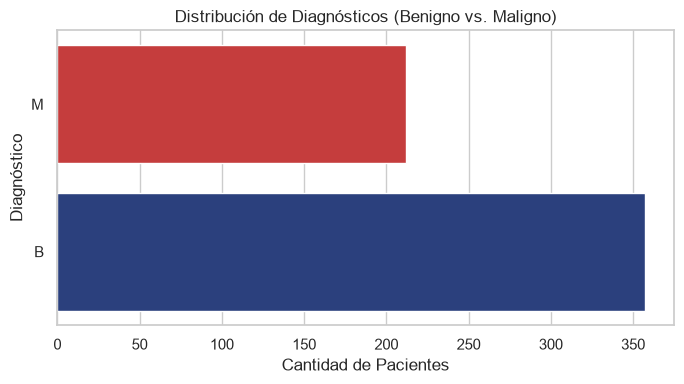

In [4]:
print(df['Diagnosis'].value_counts())

plt.figure(figsize=(7, 4))
sns.countplot(
    data=df,
    y='Diagnosis',
    hue='Diagnosis',
    palette={'B': '#1e3a8a', 'M': '#dc2626'},
    legend=False
)
plt.title('Distribución de Diagnósticos (Benigno vs. Maligno)')
plt.xlabel('Cantidad de Pacientes')
plt.ylabel('Diagnóstico')
plt.tight_layout()
plt.show()

### Histogramas, Asimetría y Diagramas de Caja (*Boxplots*)

Visualizamos la distribución de las 10 características seleccionadas junto con su media, los límites de dos desviaciones estándar ($\mu \pm 2\sigma$), su coeficiente de asimetría (`skew`) y su diagrama de caja separado por diagnóstico. No recortamos los *outliers* porque corresponden a deformaciones celulares reales de tumores malignos.

In [5]:
def show_normal_boxplot_by_columns(cols, df):
    fig, ax = plt.subplots(nrows=len(cols), ncols=2, figsize=(11, 3.3 * len(cols)), layout='constrained')
    for i, col in enumerate(cols):
        std = df[col].std()
        mean = df[col].mean()
        skew = df[col].skew()

        lim_max = mean + (std * 2)
        lim_min = mean - (std * 2)

        sns.histplot(data=df, x=col, ax=ax[i, 0], color='#1e3a8a', label=f'Skew: {skew:.2f}')
        ax[i, 0].axvline(x=lim_max, color='#dc2626', linestyle='--')
        ax[i, 0].axvline(x=lim_min, color='#dc2626', linestyle='--')
        ax[i, 0].axvline(x=mean, color='#0f172a', linestyle='-')
        ax[i, 0].set_title(f'Histograma: {col}')
        ax[i, 0].legend()

        sns.boxplot(
            data=df,
            x=col,
            y='Diagnosis',
            hue='Diagnosis',
            palette={'B': '#1e3a8a', 'M': '#dc2626'},
            legend=False,
            ax=ax[i, 1]
        )
        ax[i, 1].set_title(f'Boxplot por Diagnóstico: {col}')

    plt.show()

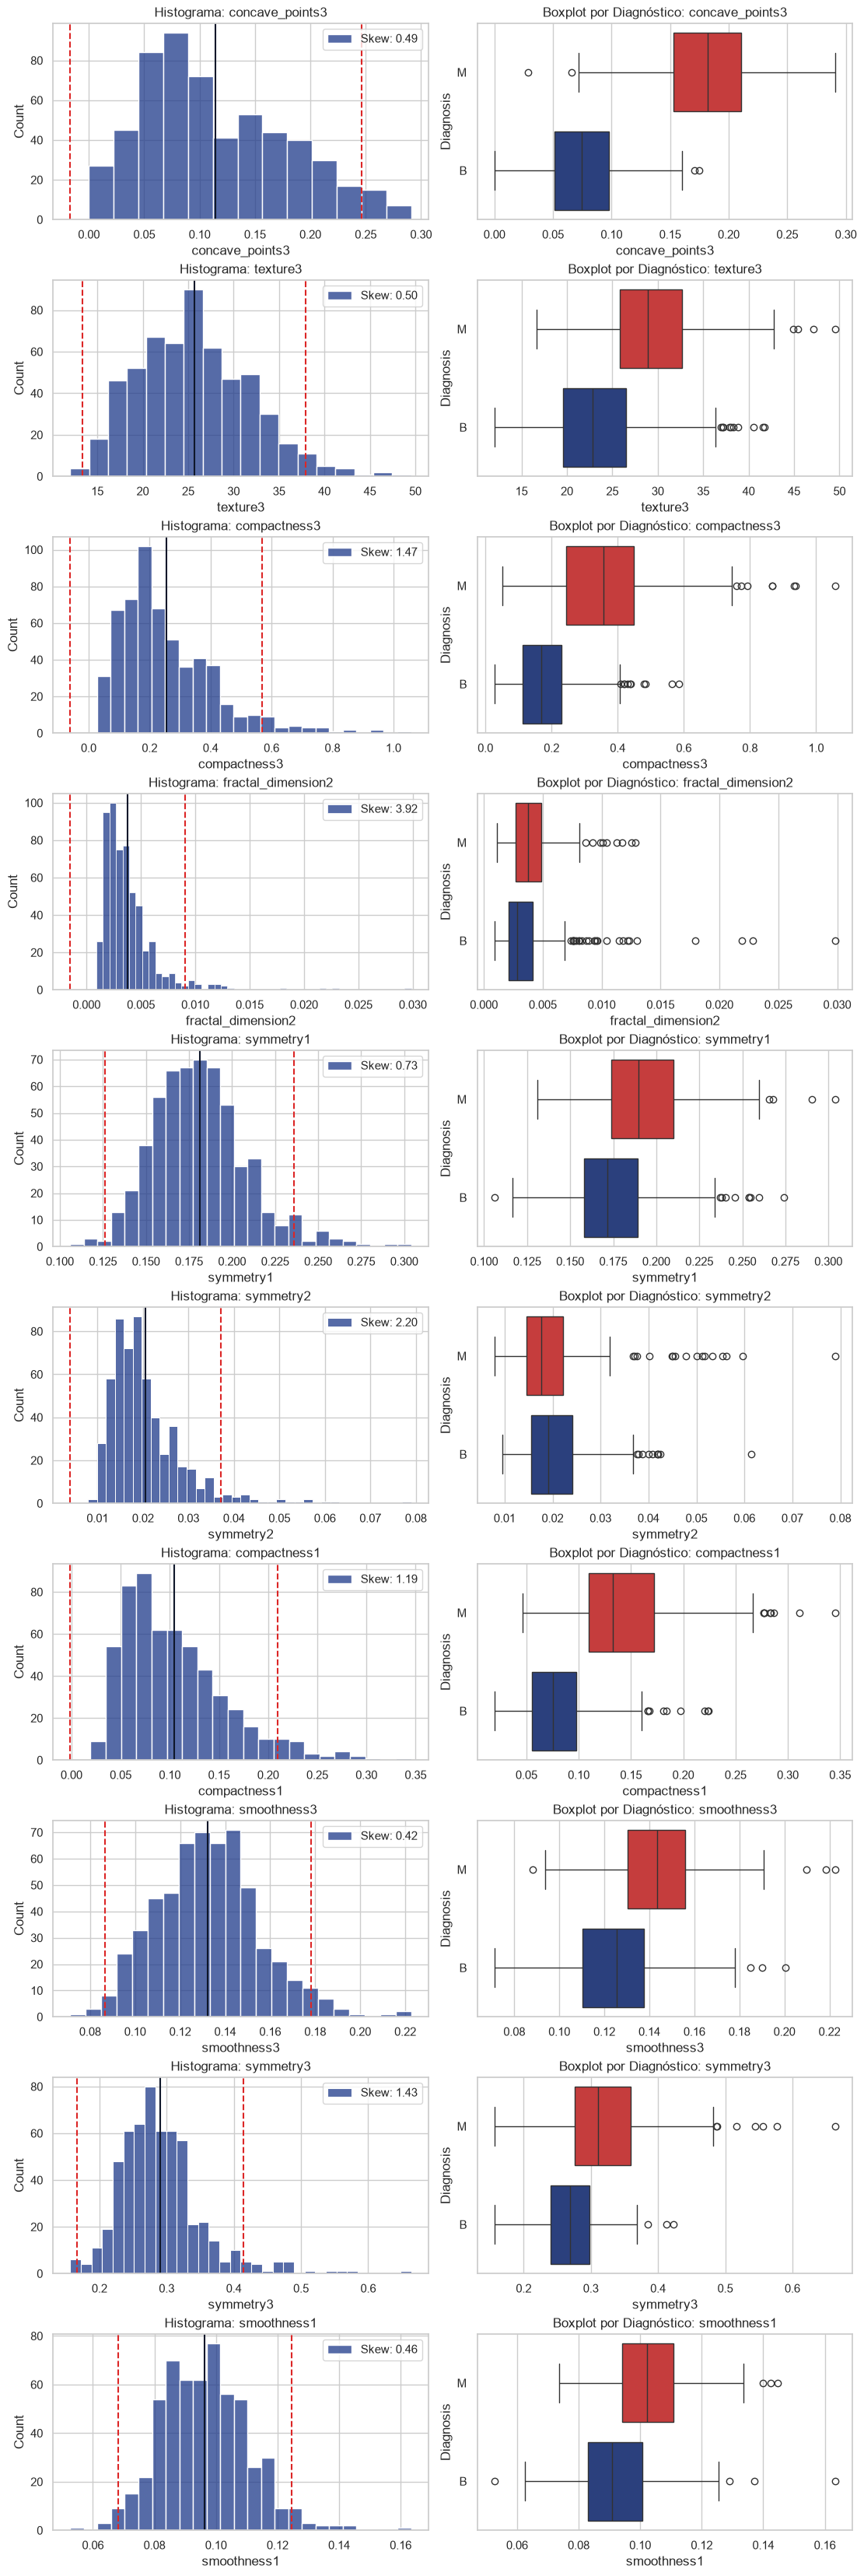

In [6]:
col = [
    'concave_points3',
    'texture3',
    'compactness3',
    'fractal_dimension2',
    'symmetry1',
    'symmetry2',
    'compactness1',
    'smoothness3',
    'symmetry3',
    'smoothness1'
]

show_normal_boxplot_by_columns(col, df)

## 4. Transformación Logarítmica y Entrenamiento del Modelo

Aplicamos las siguientes mejoras sobre el código de entrenamiento manteniendo funciones básicas:

1. **Transformación segura con `np.log1p`:** Calculamos $\log(1 + x)$ sobre una copia (`df_skewed`) para disminuir la asimetría sin convertir los `0.0` en `-inf`.
2. **Alineación de `X` e `y`:** Extraemos tanto `x_features` como `y_targets` desde el mismo DataFrame (`df_skewed`).
3. **Partición estratificada (`stratify=y_targets`):** Conserva la proporción original de tumores benignos y malignos en entrenamiento y prueba.
4. **Control de sobreajuste (*Overfitting*):** Limitamos la profundidad del árbol (`max_depth=4`) y exigimos al menos 5 muestras por hoja (`min_samples_leaf=5`).

In [7]:
df_skewed = df.copy()
df_skewed[col] = np.log1p(df_skewed[col])

x_features = df_skewed[col]
y_targets = df_skewed['Diagnosis']

x_train, x_test, y_train, y_test = train_test_split(
    x_features, y_targets, test_size=0.25, random_state=42, stratify=y_targets
)

model = DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42)
model.fit(x_train, y_train)

predictions = model.predict(x_test)

## 5. Evaluación del Modelo y Visualización del Árbol

Revisamos la exactitud (`accuracy_score`), el reporte detallado por clase (`classification_report`) —prestando especial atención al **Recall** de la clase maligna `M`— y la matriz de confusión (`confusion_matrix`).

In [ ]:
accuracy = accuracy_score(y_test, predictions)
report = classification_report(y_test, predictions)
cm = confusion_matrix(y_test, predictions, labels=['B', 'M'])

print(f'Exactitud (Accuracy): {accuracy:.4f}\n')
print('Reporte de Clasificación:')
print(report)

plt.figure(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benigno (B)', 'Maligno (M)'],
    yticklabels=['Benigno (B)', 'Maligno (M)']
)
plt.title('Matriz de Confusión')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Diagnóstico Real')
plt.tight_layout()
plt.show()

### Estructura del Árbol de Decisión Entrenado

Graficamos el árbol resultante con `plot_tree` para observar las variables y umbrales que utiliza en cada división.

In [ ]:
plt.figure(figsize=(20, 9))
plot_tree(
    model,
    feature_names=col,
    class_names=['Benigno (B)', 'Maligno (M)'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Árbol de Decisión Entrenado (Profundidad Máxima = 4)')
plt.tight_layout()
plt.show()

<div style="font-family: system-ui, -apple-system, sans-serif; max-width: 820px; margin-top: 12px; padding: 18px 22px; border: 1px solid #cbd5e1; border-left: 5px solid #1e3a8a; border-radius: 8px; background-color: #f8fafc; color: #1e293b;">
  <h3 style="margin: 0 0 8px 0; color: #0f172a; font-size: 1.1rem;">Resumen de Resultados</h3>
  <ul style="margin: 0; padding-left: 20px; line-height: 1.6;">
    <li><strong>Preprocesamiento sin pérdida de datos:</strong> Conservar los 569 pacientes y aplicar <code>np.log1p</code> evitó valores infinitos y preservó la información clínica de los ceros reales.</li>
    <li><strong>Desempeño del modelo:</strong> Con <code>max_depth=4</code> y <code>min_samples_leaf=5</code>, el árbol alcanza una exactitud del <strong>91.61 %</strong> en el conjunto de prueba sin sobreajustarse.</li>
    <li><strong>Variables clave:</strong> <code>concave_points3</code> y <code>texture3</code> encabezan las decisiones principales para distinguir tumores benignos de malignos.</li>
  </ul>
</div>